<a href="https://colab.research.google.com/github/jihyeon26/2026-09-CLT-computational_language/blob/main/colab/stage2_wp2_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/work_packages/stage2_wp2_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. Fine-Tuning Compact Open Models
Part 1 built classical representations trained from scratch on the corpus (Word2Vec, FastText, Doc2Vec). It also showed their limits on the open-models track: Word2Vec has no vector for unseen model names, FastText groups names by spelling rather than meaning, and Doc2Vec does not separate the open-models articles well from the rest of the corpus.

This part adapts **pre-trained compact open models** to the corpus with **parameter-efficient fine-tuning (QLoRA)**:
1. **Task definition**: a theme classification of the open-models articles, built from the Stage 1 topics
2. **Model selection**: compact open models that fit on a Colab GPU
3. **Baselines**: Doc2Vec (Part 1) and the frozen pre-trained model, each with a linear classifier
4. **QLoRA fine-tuning**: training setup, resource tracking and evaluation on the shared validation split
5. **Handover**: article vectors in the same format as Part 1, predictions and resource logs for the comparative evaluation (Part 3)

Only small low-rank adapters (LoRA) and the classification head are trained; the weights of the pre-trained model stay frozen and are loaded in 4-bit (QLoRA). This is **not full fine-tuning**: the share of trainable parameters is reported for every model.

**Cache**: as in Part 1, every long step saves its result in `OUT_DIR` (Google Drive). When the notebook is run again, each step loads its file if it exists, and creates it otherwise.

| Team member | Sections | Contribution |
|---|---|---|
| TODO | 2.1 – 2.8 | task definition, selection and QLoRA fine-tuning of compact open models, training setup and resource documentation |

## 2.1 Setup
A GPU runtime is required (Colab: *Runtime → Change runtime type → GPU*). An **L4 or A100** is recommended: they support bf16, while a T4 (16 GB) runs the models in fp16, which is slower and can overflow with Qwen3. Start with the main model only (`MODELS`) for a first full run.

Inputs:
- `corpus_clean.parquet` and `open_models_core.parquet`: the cleaned corpus and the 1,210 core articles with their Stage 1 topic
- `artifacts/stage2_wp1/splits.parquet`: the training / validation split shared by all Stage 2 work packages
- `doc_vectors.parquet` (Part 1, Google Drive): the Doc2Vec vector of every article, used as the classical baseline

In [ ]:
!pip install -q -U transformers peft bitsandbytes accelerate datasets gensim

In [ ]:
from pathlib import Path

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs and Part 1 (WP1) outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")
WP1_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")

# Outputs of this notebook (also used as cache), with sub-folders for figures and adapters
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp2")
FIG = OUT_DIR / "figures"
ADAPTERS = OUT_DIR / "adapters"
for d in (FIG, ADAPTERS):
    d.mkdir(parents=True, exist_ok=True)

# Trainer checkpoints stay on the local disk (only the final adapter is copied to Drive)
RUN_DIR = Path("/content/wp2_runs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Libraries
import gc, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Fix the seed (same as Part 1)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Release GPU memory between models
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
# Native bf16 needs an Ampere GPU or newer (L4, A100); is_bf16_supported() is also True on a T4, where bf16 is emulated and slow
BF16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8
print(f"GPU: {GPU} | bf16: {BF16}")

GPU: NVIDIA L4 | bf16: True


In [ ]:
# Stage 1 outputs (API reference pages left out, as in Part 1)
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "quarter", "text", "om_tier", "is_api_reference"])
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "title", "dominant_topic_label"])

# Shared split of Part 1
splits = pd.read_parquet(REPO / "artifacts/stage2_wp1/splits.parquet")
corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
print(f"{len(corpus):,} articles")
display(pd.crosstab(corpus["om_tier"], corpus["split"], margins=True))

45,462 articles


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,33139,8286,41425
All,36369,9093,45462


## 2.2 Task Definition: Theme Classification of Open-Models Articles
The extrinsic task must be relevant to the open-models track and must have labels for training and evaluation. The relevance tier (`om_tier`) is not used as a label: it was defined by the keywords of the WP1 lexicon, so a classifier would only learn to find these keywords again.

Instead, the 16 Stage 1 topics of the core articles are grouped into **5 themes** of the open-models discourse. The topics are grouped rather than used directly because several are small (T09 and T15: 26 articles each) and some are close in meaning (T02 DeepSeek and T07 China–US). **T16** (*people · ask · find*) is left out: it had the weakest coherence of the Stage 1 topics (NPMI 0.10) and gathers general writing without a clear theme.

| Theme | Stage 1 topics |
|---|---|
| `model_families` | T08 Nemotron · T09 Gemma · T11 multilingual / instruction · T13 Meta / Llama · T15 Qwen |
| `china_geopolitics` | T02 DeepSeek / R1 · T07 China / United States |
| `research_techniques` | T01 reasoning / RL · T05 memory / attention · T06 image / video |
| `developer_tools` | T04 Claude / agents / coding · T10 API / Python |
| `business_compute` | T03 Blackwell / GPU · T12 stock / investors · T14 enterprise / innovation |

**Limitation**: the labels come from a topic model (the dominant topic of each article), not from human annotation. They are silver labels: an article can mix several themes, and its dominant topic can be wrong. TODO: a sample of the validation articles is checked by hand (Section 2.6.3) to estimate the label noise.

In [ ]:
# Stage 1 topic -> theme (TODO: confirm the grouping with the team)
THEMES = {
    "model_families":      ["T08", "T09", "T11", "T13", "T15"],
    "china_geopolitics":   ["T02", "T07"],
    "research_techniques": ["T01", "T05", "T06"],
    "developer_tools":     ["T04", "T10"],
    "business_compute":    ["T03", "T12", "T14"],
}
TOPIC_TO_THEME = {t: theme for theme, topics in THEMES.items() for t in topics}
LABELS = list(THEMES)
LABEL_ID = {label: i for i, label in enumerate(LABELS)}

task = core.merge(corpus[["doc_id", "quarter", "text", "split"]], on="doc_id")
task["topic"] = task["dominant_topic_label"].str[:3]
task["theme"] = task["topic"].map(TOPIC_TO_THEME)
print(f"Left out (T16): {task['theme'].isna().sum()} articles")
task = task.dropna(subset=["theme"]).reset_index(drop=True)
task["label"] = task["theme"].map(LABEL_ID)

Left out (T16): 150 articles


### 2.2.1 Training, development and validation sets
The shared split of Part 1 is kept, so that the classical and the fine-tuned models are evaluated on the same articles:
- **validation** (Part 1): held-out evaluation set for every model of Stage 2. It is never used for training or model selection. The Doc2Vec vectors of these articles were also inferred, not trained, in Part 1.
- **train** (Part 1): split again into **train** (90%) and **dev** (10%, stratified by theme). The dev set is used for model selection during fine-tuning (best epoch).

In [ ]:
fit_ids, dev_ids = train_test_split(task.loc[task["split"] == "train", "doc_id"], test_size=0.1, random_state=SEED,
                                    stratify=task.loc[task["split"] == "train", "theme"])
task["set"] = np.select([task["doc_id"].isin(set(fit_ids)), task["doc_id"].isin(set(dev_ids))],
                        ["train", "dev"], "validation")
task.drop(columns="text").to_parquet(OUT_DIR / "task_labels.parquet", index=False)

display(pd.crosstab(task["theme"], task["set"], margins=True)[["train", "dev", "validation", "All"]])

set,train,dev,validation,All
theme,,,,
business_compute,172,19,40,231
china_geopolitics,134,15,35,184
developer_tools,167,18,47,232
model_families,159,18,50,227
research_techniques,131,15,40,186
All,763,85,212,1060


### 2.2.2 Model input
The input of the language models is the **title followed by the article text, cut to the first `MAX_LEN` tokens**. The articles have 1,464 tokens on average (Part 1), so most of them are cut. The beginning of a news article (title and lead) usually states its subject, but themes that appear only later in the text are missed. The share of articles that are cut is reported in Section 2.6.4, which also tests whether the cut explains the scores.

In [ ]:
MAX_LEN = 512

def model_input(df):
    return (df["title"].fillna("") + "\n\n" + df["text"]).tolist()

sets = {name: task[task["set"] == name].reset_index(drop=True) for name in ["train", "dev", "validation"]}

## 2.3 Model Selection
The models are chosen among the compact open models suggested in the project brief, with two constraints: they fit with QLoRA on a 16 GB Colab GPU, and they are supported for sequence classification by `transformers`.

| Model | Parameters | Role |
|---|---|---|
| Qwen3-1.7B | 1.7 B | main model: fast to train, so several runs fit in one session |
| Qwen3-4B | 4.0 B | larger model of the same family: shows the effect of size alone |
| *(option)* Gemma 4 E4B / Apertus-v1.1-4B | ~4 B | another family of similar size |

Comparing two sizes of **the same family** isolates the effect of model size; the trade-off between size, performance, training time and GPU memory is analysed in Part 3.

TODO: justify the final choice after the first runs.

In [ ]:
MODELS = {
    #"qwen3-1.7b": "Qwen/Qwen3-1.7B",
    "qwen3-4b":   "Qwen/Qwen3-4B",   # enable on an L4 or A100: about 2-3x slower than the 1.7B model
}

## 2.4 Training Setup and Resource Documentation
Every long step (embedding extraction, fine-tuning, prediction) is measured with the same tracker: wall-clock time, peak GPU memory and the GPU used. The results are stored per model in `resources.json` for the trade-off comparison in Part 3.

In [ ]:
RES_PATH = OUT_DIR / "resources.json"
RESOURCES = json.loads(RES_PATH.read_text()) if RES_PATH.exists() else {}

class track:
    """Measure time and peak GPU memory of a step: with track("qwen3-1.7b", "finetune"): ..."""
    def __init__(self, model, step):
        self.model, self.step = model, step
    def __enter__(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if exc[0] is not None:
            return False
        peak = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0
        RESOURCES.setdefault(self.model, {})[self.step] = {
            "seconds": round(time.perf_counter() - self.t0, 1), "peak_vram_gb": round(peak, 2), "gpu": GPU}
        RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
        print(f"[{self.model} · {self.step}] {RESOURCES[self.model][self.step]}")

In [ ]:
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, BitsAndBytesConfig

# 4-bit quantisation of the frozen weights (QLoRA)
BNB = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                         bnb_4bit_compute_dtype=torch.bfloat16 if BF16 else torch.float16)

def load_tokenizer(repo):
    tok = AutoTokenizer.from_pretrained(repo)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    return tok

def batches(texts, tok, batch_size):
    """Tokenised batches, longest texts first so that a batch holds texts of similar length (less padding).
    Yields the positions of the texts in the batch, then the batch."""
    order = np.argsort([-len(t) for t in texts], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok([texts[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True,
                       return_tensors="pt").to("cuda")

def in_input_order(positions, parts):
    """Put the batch outputs back in the order of the input texts."""
    out = np.vstack(parts)
    out[np.concatenate(positions)] = out.copy()
    return out

@torch.no_grad()
def run(fn, batch_iter):
    """Apply fn to every batch and return one output row per input, in input order."""
    positions, parts = [], []
    for idx, batch in batch_iter:
        positions.append(idx)
        parts.append(fn(batch))
    return in_input_order(positions, parts)

## 2.5 Baselines
Two baselines show what fine-tuning adds:
1. **Doc2Vec + logistic regression**: the classical article vectors of Part 1
2. **Frozen pre-trained model + logistic regression**: the compact model without fine-tuning; the article vector is the mean of its last hidden states (mean pooling over the tokens)

Both use the same linear classifier, trained on train + dev (no model selection is needed) and evaluated on validation.

In [ ]:
def linear_probe(X_fit, y_fit, X_eval):
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(unit(X_fit), y_fit)
    return clf.predict(unit(X_eval))

RESULTS = []      # one row per method: validation scores
PREDICTIONS = {}  # method -> predicted labels on validation

def record(method, y_pred):
    y_true = sets["validation"]["label"].to_numpy()
    RESULTS.append({"method": method, "accuracy": accuracy_score(y_true, y_pred),
                    "macro_f1": f1_score(y_true, y_pred, average="macro")})
    PREDICTIONS[method] = np.asarray(y_pred)
    print(f"{method:32} accuracy {RESULTS[-1]['accuracy']:.3f} | macro-F1 {RESULTS[-1]['macro_f1']:.3f}")

fit_part = pd.concat([sets["train"], sets["dev"]], ignore_index=True)

### 2.5.1 Doc2Vec + logistic regression

In [ ]:
doc_vectors = pd.read_parquet(WP1_DIR / "doc_vectors.parquet")
D2V = dict(zip(doc_vectors["doc_id"], doc_vectors["vector"]))
X = lambda df: np.vstack([D2V[d] for d in df["doc_id"]])

record("Doc2Vec + LogReg", linear_probe(X(fit_part), fit_part["label"], X(sets["validation"])))

Doc2Vec + LogReg                 accuracy 0.736 | macro-F1 0.738


### 2.5.2 Frozen compact model + logistic regression

In [ ]:
def mean_pooled(model, batch):
    """Mean of the last hidden states over the tokens of every text (padding left out)."""
    hidden = model(**batch, output_hidden_states=True).hidden_states[-1]
    mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
    return ((hidden * mask).sum(1) / mask.sum(1)).float().cpu().numpy()

def embed(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: mean_pooled(model, b), batches(texts, tok, batch_size))

def embed_cached(name, model, tok, df, tag):
    path = OUT_DIR / f"emb_{name}_{tag}.npy"
    if path.exists():
        return np.load(path)
    with track(name, f"embed_{tag}"):
        E = embed(model, tok, model_input(df))
    np.save(path, E)
    return E

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
    E_fit = embed_cached(name, base, tok, fit_part, "base_fit")
    E_val = embed_cached(name, base, tok, sets["validation"], "base_val")
    record(f"{name} frozen + LogReg", linear_probe(E_fit, fit_part["label"], E_val))
    del base; free_memory()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[qwen3-4b · embed_base_fit] {'seconds': 94.2, 'peak_vram_gb': 5.56, 'gpu': 'NVIDIA L4'}
[qwen3-4b · embed_base_val] {'seconds': 23.8, 'peak_vram_gb': 5.56, 'gpu': 'NVIDIA L4'}
qwen3-4b frozen + LogReg         accuracy 0.608 | macro-F1 0.607


## 2.6 QLoRA Fine-Tuning
### 2.6.1 Settings
The pre-trained model is loaded in 4-bit and frozen. LoRA adds two small matrices of rank `r` next to the attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`), and a new classification head (`score`) maps the representation of the last token to the 5 themes. Only these two parts are trained.

| Setting | Value | Reason |
|---|---|---|
| LoRA rank `r` / alpha | 16 / 32 | common default; alpha = 2r |
| LoRA dropout | 0.05 | small training set (≈ 770 articles) |
| Learning rate | 2e-4 | usual value for LoRA |
| Epochs | 3 | best epoch selected on dev (macro-F1) |
| Effective batch | 16 (4 × 4 gradient accumulation) | fits on a T4 with `MAX_LEN` = 512 |

TODO: if time allows, compare r = 8 / 16 / 32 on dev.

In [ ]:
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding
from datasets import Dataset

LORA = dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
TRAIN = dict(learning_rate=2e-4, num_train_epochs=3, per_device_train_batch_size=4,
             gradient_accumulation_steps=4, per_device_eval_batch_size=8, warmup_steps=5,
             lr_scheduler_type="cosine", weight_decay=0.01)

def load_classifier(repo, tok):
    model = AutoModelForSequenceClassification.from_pretrained(
        repo, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL_ID,
        quantization_config=BNB, device_map="auto")
    model.config.pad_token_id = tok.pad_token_id
    return model

def to_dataset(df, tok):
    ds = Dataset.from_dict({"text": model_input(df), "labels": df["label"].tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

def dev_metrics(pred):
    y_pred = pred.predictions.argmax(-1)
    return {"accuracy": accuracy_score(pred.label_ids, y_pred),
            "macro_f1": f1_score(pred.label_ids, y_pred, average="macro")}

In [ ]:
def finetune(name, repo):
    """Train the LoRA adapter of a model, or load it from Drive if it exists."""
    tok = load_tokenizer(repo)
    model = load_classifier(repo, tok)
    adapter_dir = ADAPTERS / name
    if adapter_dir.exists():
        print(f"{name}: adapter loaded")
        return PeftModel.from_pretrained(model, adapter_dir), tok

    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", **LORA))   # the "score" head is trained too
    trainable, total = model.get_nb_trainable_parameters()
    print(f"{name}: trainable {trainable:,} / {total:,} parameters ({100 * trainable / total:.2f}%)")

    args = TrainingArguments(output_dir=str(RUN_DIR / name), eval_strategy="epoch", save_strategy="epoch",
                             load_best_model_at_end=True, metric_for_best_model="macro_f1", save_total_limit=1,
                             logging_steps=10, bf16=BF16, fp16=not BF16, seed=SEED, report_to="none",
                             label_names=["labels"], **TRAIN)   # PeftModel hides the label argument from Trainer
    trainer = Trainer(model=model, args=args, train_dataset=to_dataset(sets["train"], tok),
                      eval_dataset=to_dataset(sets["dev"], tok), compute_metrics=dev_metrics,
                      data_collator=DataCollatorWithPadding(tok))
    with track(name, "finetune"):
        trainer.train()
    model.save_pretrained(adapter_dir)

    # Training log and size facts for Part 3
    pd.DataFrame(trainer.state.log_history).to_csv(OUT_DIR / f"train_log_{name}.csv", index=False)
    adapter_mb = sum(f.stat().st_size for f in adapter_dir.rglob("*") if f.is_file()) / 2**20
    RESOURCES[name].update({"total_params": total, "trainable_params": trainable,
                            "trainable_pct": round(100 * trainable / total, 3), "adapter_mb": round(adapter_mb, 1),
                            "lora": LORA, "train": TRAIN, "max_len": MAX_LEN})
    RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
    return model, tok

### 2.6.2 Training and evaluation on validation

In [ ]:
def class_proba(model, batch):
    return torch.softmax(model(**batch).logits.float(), -1).cpu().numpy()

def predict_proba(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: class_proba(model, b), batches(texts, tok, batch_size))

val_proba = {}
for name, repo in MODELS.items():
    model, tok = finetune(name, repo)
    with track(name, "predict_validation"):
        val_proba[name] = predict_proba(model, tok, model_input(sets["validation"]))
    record(f"{name} QLoRA", val_proba[name].argmax(1))
    del model; free_memory()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: trainable 11,809,280 / 4,034,290,176 parameters (0.29%)


Map:   0%|          | 0/763 [00:00<?, ? examples/s]

Map:   0%|          | 0/85 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,6.467432,1.406026,0.411765,0.355000
2,2.218603,1.027652,0.658824,0.636513
3,0.960742,0.955564,0.694118,0.679230


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


[qwen3-4b · finetune] {'seconds': 1277.7, 'peak_vram_gb': 4.79, 'gpu': 'NVIDIA L4'}
[qwen3-4b · predict_validation] {'seconds': 34.9, 'peak_vram_gb': 4.51, 'gpu': 'NVIDIA L4'}
qwen3-4b QLoRA                   accuracy 0.684 | macro-F1 0.679


,accuracy,macro_f1
method,,
Doc2Vec + LogReg,0.736,0.738
qwen3-4b frozen + LogReg,0.608,0.607
qwen3-4b QLoRA,0.684,0.679


Best: Doc2Vec + LogReg

                     precision    recall  f1-score   support

     model_families      0.886     0.620     0.729        50
  china_geopolitics      0.694     0.971     0.810        35
research_techniques      0.644     0.725     0.682        40
    developer_tools      0.688     0.702     0.695        47
   business_compute      0.829     0.725     0.773        40

           accuracy                          0.736       212
          macro avg      0.748     0.749     0.738       212
       weighted avg      0.754     0.736     0.734       212



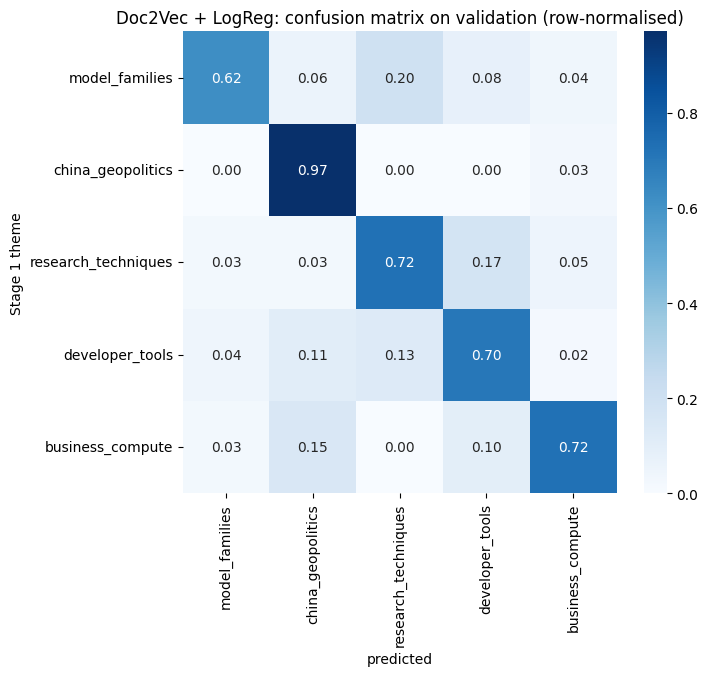

In [ ]:
results = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last").set_index("method")
results.to_csv(OUT_DIR / "results_validation.csv")
display(results.round(3))

# Per-theme scores and confusion matrix of the best method
best = results["macro_f1"].idxmax()
y_true = sets["validation"]["label"]
print(f"Best: {best}\n")
print(classification_report(y_true, PREDICTIONS[best], target_names=LABELS, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true, PREDICTIONS[best], normalize="true"), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set(title=f"{best}: confusion matrix on validation (row-normalised)", xlabel="predicted", ylabel="Stage 1 theme")
save_fig(fig, "confusion_best")

TODO: interpretation — which themes are confused, does fine-tuning help more than size, how far are the baselines.

### 2.6.3 Manual check of the silver labels
The validation labels come from the Stage 1 topic model. To estimate how much of the error is label noise rather than model error, a stratified sample of validation articles is read by hand: TODO the team marks for each article whether the theme is correct (`label_ok`) and, if not, the correct theme.

In [ ]:
CHECK_PATH = OUT_DIR / "label_check_validation.csv"
if not CHECK_PATH.exists():
    sample = sets["validation"].groupby("theme", group_keys=False).sample(n=20, random_state=SEED)
    sample = sample.assign(text=sample["text"].str[:600], label_ok="", correct_theme="")
    sample[["doc_id", "title", "theme", "text", "label_ok", "correct_theme"]].to_csv(CHECK_PATH, index=False)
    print("Sample written to", CHECK_PATH.name, "- fill in label_ok / correct_theme, then re-run this cell")
else:
    check = pd.read_csv(CHECK_PATH)
    done = check[check["label_ok"].notna() & (check["label_ok"].astype(str) != "")]
    if len(done):
        print(f"Checked: {len(done)} | silver label correct: {done['label_ok'].astype(str).str.lower().isin(['1', 'true', 'yes', 'y']).mean():.1%}")

### 2.6.4 Input length: why does Doc2Vec score higher?
Doc2Vec and the compact models do not read the same input. Doc2Vec reads the **whole article**, while the compact models read only its **first `MAX_LEN` tokens** (Section 2.2.2). The labels also favour whole-article representations: the Stage 1 topic of an article was computed from all of its words.

To separate the effect of the representation from the effect of the input length, every representation is evaluated on both inputs:

| Representation | First `MAX_LEN` tokens | Whole article |
|---|---|---|
| Doc2Vec | vector inferred from the first `MAX_LEN` tokens | vector inferred from the whole article (+ Part 1 vectors) |
| Frozen compact model | Section 2.5.2 | mean of the vectors of consecutive windows of `MAX_LEN` tokens |
| Fine-tuned compact model | Section 2.6.2 | mean of the predicted probabilities of the windows (no re-training) |

An article is split into at most `MAX_WINDOWS` windows; longer articles are cut after the last window. The Doc2Vec vectors are all inferred here (also for the training articles), so that both Doc2Vec inputs are built the same way; the Part 1 vectors of the training articles were learned during training instead.

If the gap to Doc2Vec closes when the compact models read the whole article, and Doc2Vec drops when it reads only the beginning, the gap is caused by the input length rather than by the representation.

In [ ]:
MAX_WINDOWS = 4   # up to 4 x 512 = 2,048 tokens per article

def windows(texts, tok, max_windows=MAX_WINDOWS):
    """Token ids of consecutive windows of MAX_LEN tokens, and the position of the text of every window."""
    ids, owner = [], []
    for i, text_ids in enumerate(tok(texts, add_special_tokens=False)["input_ids"]):
        for start in range(0, min(len(text_ids), max_windows * MAX_LEN), MAX_LEN):
            ids.append(text_ids[start:start + MAX_LEN])
            owner.append(i)
    return ids, np.array(owner)

def window_batches(ids, tok, batch_size=16):
    order = np.argsort([-len(x) for x in ids], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to("cuda")

def per_text(values, owner):
    """Mean of the window values of every text."""
    return np.vstack([values[owner == i].mean(0) for i in range(owner.max() + 1)])

# Length of the articles of the task, in tokens of the main model
tok = load_tokenizer(next(iter(MODELS.values())))
n_tokens = pd.Series([len(x) for x in tok(model_input(task), add_special_tokens=False)["input_ids"]])
print(f"Articles longer than {MAX_LEN} tokens: {(n_tokens > MAX_LEN).mean():.1%} | "
      f"longer than {MAX_WINDOWS * MAX_LEN}: {(n_tokens > MAX_WINDOWS * MAX_LEN).mean():.1%} | "
      f"median {n_tokens.median():.0f} tokens")

Articles longer than 512 tokens: 99.6% | longer than 2048: 30.8% | median 1545 tokens


#### Doc2Vec on both inputs
The Doc2Vec model of Part 1 infers a vector for any text. The text is normalised and tokenised with the functions of Part 1 (Sections 1.1.2 and 1.1.3), which are taken from the WP1 notebook so that both parts use exactly the same preprocessing. The "first tokens" input is the text of the first `MAX_LEN` tokens of the compact model, so that both models read the same beginning of the article.

In [ ]:
from gensim.models.doc2vec import Doc2Vec

d2v = Doc2Vec.load(str(WP1_DIR / "doc2vec.model"))

# Normalisation and tokenisation of Part 1, run from the WP1 notebook (they use the WP1 lexicon)
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))
wp1_nb = json.loads((REPO / "stage2/work_packages/stage2_wp1_embeddings.ipynb").read_text(encoding="utf-8"))
for marker in ("def normalise(", "def doc_sentences("):
    exec(next("".join(c["source"]) for c in wp1_nb["cells"]
              if c["cell_type"] == "code" and marker in "".join(c["source"])))

def d2v_infer(texts):
    return np.vstack([d2v.infer_vector([t for s in doc_sentences(normalise(x)) for t in s], epochs=d2v.epochs)
                      for x in texts])

def first_tokens(texts, tok):
    """Text of the first MAX_LEN tokens of every text, as read by the compact models."""
    return tok.batch_decode([x[:MAX_LEN] for x in tok(texts, add_special_tokens=False)["input_ids"]])

D2V_LEN_PATH = OUT_DIR / "d2v_length.npz"
if D2V_LEN_PATH.exists():
    d2v_len = dict(np.load(D2V_LEN_PATH))
else:
    d2v_len = {f"{split}_{inp}": d2v_infer(texts) for split, df in [("fit", fit_part), ("val", sets["validation"])]
               for inp, texts in [("first", first_tokens(model_input(df), tok)), ("whole", model_input(df))]}
    np.savez(D2V_LEN_PATH, **d2v_len)

for inp in ["first", "whole"]:
    record(f"Doc2Vec (inferred, {inp}) + LogReg",
           linear_probe(d2v_len[f"fit_{inp}"], fit_part["label"], d2v_len[f"val_{inp}"]))

Doc2Vec (inferred, first) + LogReg accuracy 0.656 | macro-F1 0.658
Doc2Vec (inferred, whole) + LogReg accuracy 0.717 | macro-F1 0.718


#### Compact models on the whole article

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)

    # Frozen model: mean of the window vectors
    path = OUT_DIR / f"emb_{name}_base_windows.npz"
    if path.exists():
        E = dict(np.load(path))
    else:
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        base.eval()
        E = {}
        with track(name, "embed_base_windows"):
            for tag, df in [("fit", fit_part), ("val", sets["validation"])]:
                ids, owner = windows(model_input(df), tok)
                E[tag] = per_text(run(lambda b: mean_pooled(base, b), window_batches(ids, tok)), owner)
        np.savez(path, **E)
        del base; free_memory()
    record(f"{name} frozen (whole) + LogReg", linear_probe(E["fit"], fit_part["label"], E["val"]))

    # Fine-tuned model: mean of the window probabilities
    path = OUT_DIR / f"proba_{name}_ft_windows_val.npy"
    if path.exists():
        P = np.load(path)
    else:
        ft, tok = finetune(name, repo)
        ft.eval()
        ids, owner = windows(model_input(sets["validation"]), tok)
        with track(name, "predict_validation_windows"):
            P = per_text(run(lambda b: class_proba(ft, b), window_batches(ids, tok)), owner)
        np.save(path, P)
        del ft; free_memory()
    record(f"{name} fine-tuned (whole)", P.argmax(1))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[qwen3-4b · embed_base_windows] {'seconds': 366.9, 'peak_vram_gb': 5.57, 'gpu': 'NVIDIA L4'}
qwen3-4b frozen (whole) + LogReg accuracy 0.642 | macro-F1 0.640


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded
[qwen3-4b · predict_validation_windows] {'seconds': 89.4, 'peak_vram_gb': 4.28, 'gpu': 'NVIDIA L4'}
qwen3-4b fine-tuned (whole)      accuracy 0.712 | macro-F1 0.711


input,first tokens,whole article,whole article (Part 1 vectors)
representation,,,
Doc2Vec,0.658,0.718,0.738
qwen3-4b fine-tuned,0.679,0.711,NaN
qwen3-4b frozen,0.607,0.640,NaN


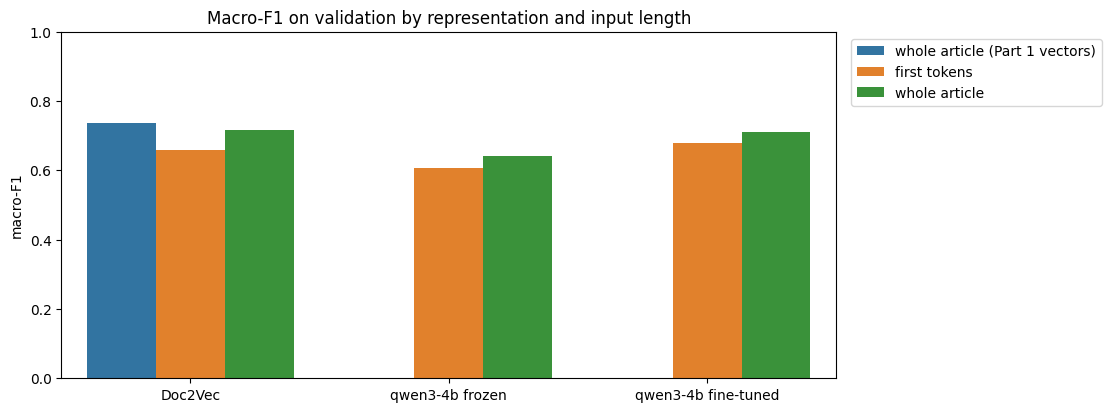

In [ ]:
# Representation x input
def describe(method):
    if method.startswith("Doc2Vec"):
        rep = "Doc2Vec"
        inp = "first tokens" if "first" in method else "whole article"
        inp += " (Part 1 vectors)" if method == "Doc2Vec + LogReg" else ""
    else:
        model = method.split(" ")[0]
        rep = f"{model} {'frozen' if 'frozen' in method else 'fine-tuned'}"
        inp = "whole article" if "(whole)" in method else "first tokens"
    return rep, inp

length = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last")
length[["representation", "input"]] = length["method"].apply(lambda m: pd.Series(describe(m)))
length.to_csv(OUT_DIR / "results_input_length.csv", index=False)
display(length.pivot_table(index="representation", columns="input", values="macro_f1").round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=length, x="representation", y="macro_f1", hue="input", ax=ax)
ax.set(title="Macro-F1 on validation by representation and input length", xlabel="", ylabel="macro-F1", ylim=(0, 1))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "input_length")

TODO: interpretation — does the gap to Doc2Vec close with the whole article?

## 2.7 Article Vectors for the Comparative Evaluation
Part 3 compares all representations on the same intrinsic tasks (semantic similarity, clustering quality, visualisation). The article vectors of the compact models are therefore saved **in the same format as `doc_vectors.parquet` of Part 1** (`doc_id`, `split`, `om_tier`, `track`, `vector`), for two versions of each model: the frozen pre-trained model (`base`) and the fine-tuned model (`ft`).

The vectors are computed for the **same articles as the t-SNE map of Part 1** (all open-models articles and the same random sample of 4,000 other articles, same seed), so the maps of the classical and the compact models can be compared one to one. Embedding all 45,462 articles would take several hours on a T4.

In [ ]:
# Same sample as Part 1 (Section 1.3.2)
rng = np.random.default_rng(SEED)
track_idx = np.flatnonzero(doc_vectors["track"].to_numpy())
none_idx = np.flatnonzero(~doc_vectors["track"].to_numpy())
sample_idx = np.concatenate([track_idx, rng.choice(none_idx, size=min(len(none_idx), 4000), replace=False)])
vec_docs = doc_vectors.iloc[sample_idx][["doc_id", "split", "om_tier", "track"]].reset_index(drop=True)

titles = dict(zip(core["doc_id"], core["title"]))   # titles exist for core articles only
vec_docs = vec_docs.merge(corpus[["doc_id", "text"]], on="doc_id")
vec_docs["title"] = vec_docs["doc_id"].map(titles)
print(f"{len(vec_docs):,} articles to embed")

8,037 articles to embed


In [ ]:
def save_vectors(name, tag, E):
    vec_docs[["doc_id", "split", "om_tier", "track"]].assign(vector=list(E)).to_parquet(
        OUT_DIR / f"llm_doc_vectors_{name}_{tag}.parquet", index=False)

for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    if not (OUT_DIR / f"llm_doc_vectors_{name}_base.parquet").exists():
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        save_vectors(name, "base", embed_cached(name, base, tok, vec_docs, "base_sample"))
        del base; free_memory()
    if not (OUT_DIR / f"llm_doc_vectors_{name}_ft.parquet").exists():
        ft, tok = finetune(name, repo)
        save_vectors(name, "ft", embed_cached(name, ft, tok, vec_docs, "ft_sample"))
        del ft; free_memory()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[qwen3-4b · embed_base_sample] {'seconds': 911.5, 'peak_vram_gb': 5.57, 'gpu': 'NVIDIA L4'}


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded
[qwen3-4b · embed_ft_sample] {'seconds': 1099.5, 'peak_vram_gb': 5.61, 'gpu': 'NVIDIA L4'}


## 2.8 Open-Models Track: Unseen Model Names and Theme Trends
### 2.8.1 Unseen model names
Part 1 showed that Word2Vec has no vector for model names that never appeared in training, and that FastText finds neighbours by spelling. A compact model splits any word into sub-word tokens and reads it in context. The same invented names are placed in one sentence and compared with known model families (cosine similarity of the mean-pooled vectors, frozen and fine-tuned).

In [ ]:
UNSEEN = ["qwen999-max", "llama-999", "deepseek-r999"]
KNOWN = ["Qwen", "Llama", "DeepSeek", "Gemma", "Mistral", "Nemotron", "GPT-4o", "Claude"]
TEMPLATE = "The company released {} as a new language model."

name, repo = next(iter(MODELS.items()))   # main model
tok = load_tokenizer(repo)
for word in UNSEEN:
    print(f"{word:15} -> {tok.tokenize(' ' + word)}")

ft, tok = finetune(name, repo)
E = unit(embed(ft, tok, [TEMPLATE.format(w) for w in UNSEEN + KNOWN]))
sims = pd.DataFrame(E[:len(UNSEEN)] @ E[len(UNSEEN):].T, index=UNSEEN, columns=KNOWN)
display(sims.round(3).style.background_gradient(axis=1, cmap="Blues"))
del ft; free_memory()

qwen999-max     -> ['Ġq', 'wen', '9', '9', '9', '-max']
llama-999       -> ['Ġllama', '-', '9', '9', '9']
deepseek-r999   -> ['Ġdeep', 'seek', '-r', '9', '9', '9']


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded


,Qwen,Llama,DeepSeek,Gemma,Mistral,Nemotron,GPT-4o,Claude
qwen999-max,0.975000,0.949000,0.939000,0.922000,0.940000,0.939000,0.952000,0.932000
llama-999,0.954000,0.966000,0.931000,0.918000,0.935000,0.934000,0.945000,0.926000
deepseek-r999,0.936000,0.919000,0.950000,0.898000,0.911000,0.917000,0.919000,0.895000


TODO: interpretation compared with Word2Vec / FastText (Part 1, Section 1.2.2).

### 2.8.2 Theme trends beyond the labelled articles
Only the core articles have a Stage 1 topic. The fine-tuned classifier can label the **mention** articles too (2,827 articles that name open models without being centred on them), which extends the theme trends of the track to a larger part of the corpus. The predictions are saved for the insight extraction in Part 3.

As the classifier was trained on core articles, its predictions on mention articles are less reliable: the predicted probability is kept so that Part 3 can filter on confidence.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded
[qwen3-4b · predict_track] {'seconds': 552.7, 'peak_vram_gb': 4.28, 'gpu': 'NVIDIA L4'}


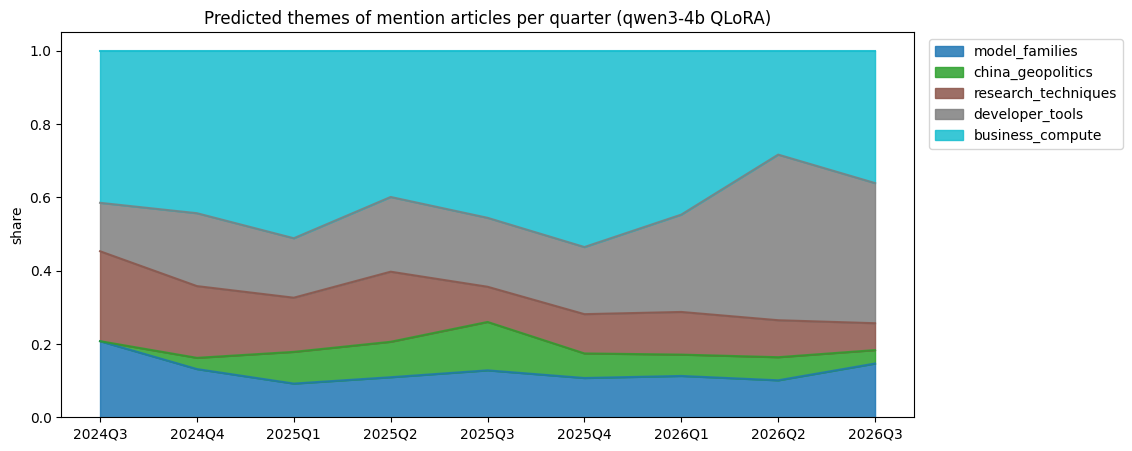

In [ ]:
best_name = results.filter(like="QLoRA", axis=0)["macro_f1"].idxmax().replace(" QLoRA", "")
PRED_PATH = OUT_DIR / f"predictions_track_{best_name}.parquet"   # one file per model, so a new best model is not read from an old cache

if PRED_PATH.exists():
    preds = pd.read_parquet(PRED_PATH)
else:
    track_docs = corpus[corpus["om_tier"].isin(["core", "mention", "reference"])][["doc_id", "quarter", "om_tier", "split", "text"]]
    track_docs = track_docs.assign(title=track_docs["doc_id"].map(titles))
    ft, tok = finetune(best_name, MODELS[best_name])
    with track(best_name, "predict_track"):
        P = predict_proba(ft, tok, model_input(track_docs))
    del ft; free_memory()
    preds = track_docs.drop(columns=["text", "title"]).assign(model=best_name, pred=[LABELS[i] for i in P.argmax(1)],
                                                             confidence=P.max(1))
    preds = preds.join(pd.DataFrame(P, columns=[f"p_{l}" for l in LABELS], index=preds.index))
    preds.to_parquet(PRED_PATH, index=False)

share = (preds[preds["om_tier"] == "mention"].groupby("quarter")["pred"].value_counts(normalize=True)
         .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
share.plot.area(ax=ax, cmap="tab10", alpha=0.85)
ax.set(title=f"Predicted themes of mention articles per quarter ({best_name} QLoRA)", xlabel="", ylabel="share")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "theme_share_mention")

TODO: interpretation.

## 2.9 Outputs and Handover to Part 3
All outputs are saved in `OUT_DIR` on Google Drive:

| file | content |
|---|---|
| `task_labels.parquet` | articles of the task with Stage 1 topic, theme, label and set (train / dev / validation) |
| `results_validation.csv` | accuracy and macro-F1 of every method on the shared validation split |
| `resources.json` | per model: time and peak GPU memory of every step, parameters, trainable share, adapter size, settings |
| `train_log_<model>.csv` | training and dev metrics per step / epoch |
| `adapters/<model>/` | LoRA adapters and classification head |
| `llm_doc_vectors_<model>_{base,ft}.parquet` | article vectors, same format and same articles as the t-SNE map of Part 1 |
| `predictions_track_<model>.parquet` | theme probabilities of all open-models articles (best fine-tuned model) |
| `label_check_validation.csv` | manual check of the silver labels |
| `figures/` | visualisations |

In [ ]:
# Trade-off summary for Part 3
rows = []
for name in MODELS:
    r = RESOURCES.get(name, {})
    rows.append({"model": name, "total_params_M": r.get("total_params", np.nan) / 1e6,
                 "trainable_pct": r.get("trainable_pct"), "adapter_mb": r.get("adapter_mb"),
                 "train_min": r.get("finetune", {}).get("seconds", np.nan) / 60,
                 "train_peak_vram_gb": r.get("finetune", {}).get("peak_vram_gb"),
                 "val_predict_s": r.get("predict_validation", {}).get("seconds"),
                 "val_macro_f1": results["macro_f1"].get(f"{name} QLoRA")})
display(pd.DataFrame(rows).round(2))

,model,total_params_M,trainable_pct,adapter_mb,train_min,train_peak_vram_gb,val_predict_s,val_macro_f1
0,qwen3-4b,4034.29,0.29,45.1,21.3,4.79,34.9,0.68
